<a href="https://colab.research.google.com/github/chitrasavithri176-cmyk/python-ex/blob/main/Olist_Brazilian_Ecommerce_Data_Science_Project_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Olist Brazilian E-Commerce — Data Science Project



## 1. Install and import libraries

In [6]:
!pip -q install pandas numpy matplotlib seaborn scipy scikit-learn statsmodels nltk tensorflow joblib pyspark

In [7]:
import os, re, json, logging, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay,
    mean_absolute_error, mean_squared_error, r2_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import cosine_similarity
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
import joblib

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s")
logger = logging.getLogger("olist_project")

RANDOM_STATE = 42
DATA_DIR = Path("/content/olist_data")
OUTPUT_DIR = Path("/content/olist_outputs")
MODEL_DIR = OUTPUT_DIR / "models"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Libraries ready.")


Libraries ready.


## 2. Load all required CSV files

In [8]:
FILES = {
    "customers": "olist_customers_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "category_translation": "product_category_name_translation.csv",
}

# Fallback to direct /content if /content/olist_data does not exist or files are directly in /content
import os

def load_csv(filename: str) -> pd.DataFrame:
    path = DATA_DIR / filename
    if not path.exists():
        fallback_path = Path("/content") / filename
        if fallback_path.exists():
            return pd.read_csv(fallback_path)
        raise FileNotFoundError(f"Missing file: {path}. Check DATA_DIR and extract the Kaggle ZIP.")
    return pd.read_csv(path)

data = {name: load_csv(filename) for name, filename in FILES.items()}

for name, frame in data.items():
    logger.info("%s loaded: %s rows, %s columns", name, *frame.shape)

customers = data["customers"].drop_duplicates().copy()
orders = data["orders"].drop_duplicates().copy()
items = data["items"].drop_duplicates().copy()
payments = data["payments"].drop_duplicates().copy()
reviews = data["reviews"].drop_duplicates().copy()
products = data["products"].drop_duplicates().copy()
sellers = data["sellers"].drop_duplicates().copy()
category_translation = data["category_translation"].drop_duplicates().copy()

## 3. Data quality checks and date conversion

In [9]:
date_cols = [
    "order_purchase_timestamp", "order_approved_at",
    "order_delivered_carrier_date", "order_delivered_customer_date",
    "order_estimated_delivery_date"
]
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

print("Orders:", orders.shape)
print("Duplicate order IDs:", orders["order_id"].duplicated().sum())
display(pd.DataFrame({
    "missing_count": orders.isna().sum(),
    "missing_percent": (orders.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False))


Orders: (99441, 8)
Duplicate order IDs: 0


,missing_count,missing_percent
order_delivered_customer_date,2965,2.98
order_delivered_carrier_date,1783,1.79
order_approved_at,160,0.16
order_id,0,0.00
order_purchase_timestamp,0,0.00
order_status,0,0.00
customer_id,0,0.00
order_estimated_delivery_date,0,0.00


## 4. Aggregate one-to-many tables before merging

In [6]:
# One row per order in each aggregate table.
item_agg = items.groupby("order_id").agg(
    item_revenue=("price", "sum"),
    freight_value=("freight_value", "sum"),
    item_count=("order_item_id", "count"),
    unique_products=("product_id", "nunique"),
    first_product_id=("product_id", "first"),
    first_seller_id=("seller_id", "first")
).reset_index()

payment_agg = payments.groupby("order_id").agg(
    payment_value=("payment_value", "sum"),
    payment_installments=("payment_installments", "max"),
    payment_type=("payment_type", "first")
).reset_index()

review_agg = reviews.groupby("order_id").agg(
    review_score=("review_score", "mean"),
    review_text=("review_comment_message", "first")
).reset_index()

# Safely reset products by dropping the translated column if it already exists from a previous run
if "product_category_name_english" in products.columns:
    products = products.drop(columns=["product_category_name_english"])

products["product_category_name"] = products["product_category_name"].fillna("unknown")
products = products.merge(category_translation, on="product_category_name", how="left")
products["product_category_name_english"] = products[
    "product_category_name_english"
].fillna(products["product_category_name"])

product_lookup = products[[
    "product_id", "product_category_name_english",
    "product_weight_g", "product_length_cm",
    "product_height_cm", "product_width_cm"
]].drop_duplicates("product_id")

# Item-level analysis table: one row per order item.
item_level = (
    items.merge(orders, on="order_id", how="left")
         .merge(customers, on="customer_id", how="left")
         .merge(product_lookup, on="product_id", how="left")
)

# Order-level analysis table: one row per order.
order_level = (
    orders.merge(customers, on="customer_id", how="left")
          .merge(item_agg, on="order_id", how="left")
          .merge(payment_agg, on="order_id", how="left")
          .merge(review_agg, on="order_id", how="left")
)

order_level["order_revenue"] = order_level["item_revenue"].fillna(0)
order_level["order_total_with_freight"] = (
    order_level["item_revenue"].fillna(0) + order_level["freight_value"].fillna(0)
)

print("Order-level:", order_level.shape)
print("Item-level:", item_level.shape)
print("Unique orders:", order_level["order_id"].nunique())

Order-level: (99441, 25)
Item-level: (112650, 23)
Unique orders: 99441


## 5.**SQL Analytics**

In [7]:
import sqlite3

# Use the output directory defined earlier in the notebook
db_path = OUTPUT_DIR / "olist.db"

# Map active DataFrames to their respective SQL table names
tables = {
    "orders": orders,
    "customers": customers,
    "order_items": items,
    "order_payments": payments,
    "order_reviews": reviews,
    "products": products,
    "sellers": sellers
}

with sqlite3.connect(db_path) as conn:
    for name, df in tables.items():
        df.to_sql(name, conn, if_exists="replace", index=False)

    # Write order-level merged analysis table
    order_level.to_sql(
        "orders_merged", conn,
        if_exists="replace", index=False
    )

print(f"Database successfully created and populated at: {db_path}")

Database successfully created and populated at: /content/olist_outputs/olist.db


**SQL Queries**

In [8]:
import sqlite3
import pandas as pd

# Create an in-memory SQLite database and connection
conn = sqlite3.connect(":memory:")

# Write the loaded DataFrames to SQLite tables matching your query references
orders.to_sql("orders", conn, if_exists="replace", index=False)
customers.to_sql("customers", conn, if_exists="replace", index=False)
items.to_sql("order_items", conn, if_exists="replace", index=False)
payments.to_sql("order_payments", conn, if_exists="replace", index=False)
reviews.to_sql("order_reviews", conn, if_exists="replace", index=False)
products.to_sql("products", conn, if_exists="replace", index=False)

def run_query(query_title: str, query: str) -> pd.DataFrame:
    """Helper to run and display SQLite queries."""
    print(f"\n{'='*40}\nQuery: {query_title}\n{'='*40}")
    df = pd.read_sql_query(query, conn)
    display(df)
    return df

# 1. Monthly Revenue & Growth % with LAG() and CTE
query_1 = """
WITH monthly_sales AS (
    SELECT
        strftime('%Y-%m', order_purchase_timestamp) AS month,
        SUM(payment_value) AS revenue
    FROM orders o
    JOIN order_payments p ON o.order_id = p.order_id
    WHERE o.order_status = 'delivered'
    GROUP BY month
)
SELECT
    month,
    ROUND(revenue, 2) AS revenue,
    ROUND(100.0 * (revenue - LAG(revenue) OVER (ORDER BY month)) / LAG(revenue) OVER (ORDER BY month), 2) AS growth_pct
FROM monthly_sales
ORDER BY month;
"""
run_query("Monthly Revenue Growth Percentage", query_1)

# 2. Top 10 Sellers by RANK() based on Revenue
query_2 = """
WITH seller_revenue AS (
    SELECT
        seller_id,
        SUM(price) AS total_sales,
        RANK() OVER (ORDER BY SUM(price) DESC) as sales_rank
    FROM order_items
    GROUP BY seller_id
)
SELECT *
FROM seller_revenue
WHERE sales_rank <= 10;
"""
run_query("Top 10 Sellers by Revenue (RANK)", query_2)

# 3. Repeat Customer Rate Analysis
query_3 = """
WITH customer_orders AS (
    SELECT
        customer_unique_id,
        COUNT(order_id) AS order_count
    FROM customers c
    JOIN orders o ON c.customer_id = o.customer_id
    GROUP BY customer_unique_id
)
SELECT
    SUM(CASE WHEN order_count > 1 THEN 1 ELSE 0 END) AS repeat_customers,
    COUNT(customer_unique_id) AS total_customers,
    ROUND(100.0 * SUM(CASE WHEN order_count > 1 THEN 1 ELSE 0 END) / COUNT(customer_unique_id), 2) AS repeat_rate_pct
FROM customer_orders;
"""
run_query("Repeat Customer Rate", query_3)

# 4. Average Delivery Time (Days) per State
query_4 = """
SELECT
    c.customer_state,
    COUNT(o.order_id) AS total_orders,
    ROUND(AVG(julianday(o.order_delivered_customer_date) - julianday(o.order_purchase_timestamp)), 2) AS avg_delivery_days
FROM orders o
JOIN customers c ON o.customer_id = c.customer_id
WHERE o.order_delivered_customer_date IS NOT NULL
GROUP BY c.customer_state
ORDER BY avg_delivery_days DESC;
"""
run_query("Average Delivery Time Per State", query_4)

# 5. Product Category Revenue Share with CTEs
query_5 = """
WITH category_revenue AS (
    SELECT
        COALESCE(p.product_category_name, 'unknown') AS category,
        SUM(i.price) AS revenue
    FROM order_items i
    LEFT JOIN products p ON i.product_id = p.product_id
    GROUP BY category
),
total AS (
    SELECT SUM(revenue) AS total_revenue FROM category_revenue
)
SELECT
    cr.category,
    ROUND(cr.revenue, 2) AS category_revenue,
    ROUND(100.0 * cr.revenue / t.total_revenue, 2) AS revenue_share_pct
FROM category_revenue cr, total t
ORDER BY category_revenue DESC
LIMIT 10;
"""
run_query("Top 10 Product Categories by Revenue Share", query_5)

# 6. Monthly Order Cancellation Rate
query_6 = """
SELECT
    strftime('%Y-%m', order_purchase_timestamp) AS month,
    COUNT(order_id) AS total_orders,
    SUM(CASE WHEN order_status = 'canceled' THEN 1 ELSE 0 END) AS canceled_orders,
    ROUND(100.0 * SUM(CASE WHEN order_status = 'canceled' THEN 1 ELSE 0 END) / COUNT(order_id), 2) AS cancellation_rate_pct
FROM orders
GROUP BY month
ORDER BY month;
"""
run_query("Monthly Order Cancellation Rate", query_6)

# 7. Average Payment Installments and Value per Payment Type
query_7 = """
SELECT
    payment_type,
    COUNT(order_id) as transactions_count,
    ROUND(AVG(payment_installments), 1) as avg_installments,
    ROUND(AVG(payment_value), 2) as avg_payment_value
FROM order_payments
GROUP BY payment_type
ORDER BY transactions_count DESC;
"""
run_query("Payment Behavior by Payment Type", query_7)

# 8. Average Review Score and Processing Time per Order Status
query_8 = """
SELECT
    o.order_status,
    COUNT(o.order_id) AS total_orders,
    ROUND(AVG(r.review_score), 2) AS avg_review_score,
    ROUND(AVG(julianday(o.order_delivered_customer_date) - julianday(o.order_purchase_timestamp)), 2) AS avg_processing_days
FROM orders o
LEFT JOIN order_reviews r ON o.order_id = r.order_id
GROUP BY o.order_status
ORDER BY total_orders DESC;
"""
run_query("Review Score & Delivery Days by Order Status", query_8)

# 9. Top 10 High-Value Orders (Order Value vs Average Product Price in Order)
query_9 = """
WITH order_stats AS (
    SELECT
        order_id,
        COUNT(product_id) AS items_count,
        SUM(price) AS items_revenue,
        AVG(price) AS avg_item_price
    FROM order_items
    GROUP BY order_id
)
SELECT
    o.order_id,
    ost.items_count,
    ROUND(ost.items_revenue, 2) AS total_value,
    ROUND(ost.avg_item_price, 2) AS avg_item_price
FROM orders o
JOIN order_stats ost ON o.order_id = ost.order_id
ORDER BY total_value DESC
LIMIT 10;
"""
run_query("Top 10 Orders with Highest Item Value", query_9)

# 10. Sellers Who Sell Across the Most States
query_10 = """
SELECT
    i.seller_id,
    COUNT(DISTINCT c.customer_state) AS distinct_states_reached,
    COUNT(i.order_id) AS total_items_sold
FROM order_items i
JOIN orders o ON i.order_id = o.order_id
JOIN customers c ON o.customer_id = c.customer_id
GROUP BY i.seller_id
ORDER BY distinct_states_reached DESC, total_items_sold DESC
LIMIT 10;
"""
run_query("Top Sellers Reaching Most States", query_10);




Query: Monthly Revenue Growth Percentage


,month,revenue,growth_pct
0,2016-10,46566.71,NaN
1,2016-12,19.62,-99.96
2,2017-01,127545.67,649979.87
3,2017-02,271298.65,112.71
4,2017-03,414369.39,52.74
5,2017-04,390952.18,-5.65
6,2017-05,567066.73,45.05
7,2017-06,490225.60,-13.55
8,2017-07,566403.93,15.54
9,2017-08,646000.61,14.05



Query: Top 10 Sellers by Revenue (RANK)


,seller_id,total_sales,sales_rank
0,4869f7a5dfa277a7dca6462dcf3b52b2,229472.63,1
1,53243585a1d6dc2643021fd1853d8905,222776.05,2
2,4a3ca9315b744ce9f8e9374361493884,200472.92,3
3,fa1c13f2614d7b5c4749cbc52fecda94,194042.03,4
4,7c67e1448b00f6e969d365cea6b010ab,187923.89,5
5,7e93a43ef30c4f03f38b393420bc753a,176431.87,6
6,da8622b14eb17ae2831f4ac5b9dab84a,160236.57,7
7,7a67c85e85bb2ce8582c35f2203ad736,141745.53,8
8,1025f0e2d44d7041d6cf58b6550e0bfa,138968.55,9
9,955fee9216a65b617aa5c0531780ce60,135171.70,10



Query: Repeat Customer Rate


,repeat_customers,total_customers,repeat_rate_pct
0,2997,96096,3.12


... (10 outputs left out)


Query: Top 10 Orders with Highest Item Value


,order_id,items_count,total_value,avg_item_price
0,03caa2c082116e1d31e67e9ae3700499,8,13440.0,1680.00
1,736e1922ae60d0d6a89247b851902527,4,7160.0,1790.00
2,0812eb902a67711a1cb742b3cdaa65ae,1,6735.0,6735.00
3,fefacc66af859508bf1a7934eab1e97f,1,6729.0,6729.00
4,f5136e38d1a14a4dbd87dff67da82701,1,6499.0,6499.00
5,2cc9089445046817a7539d90805e6e5a,6,5934.6,989.10
6,a96610ab360d42a2e5335a3998b4718a,1,4799.0,4799.00
7,199af31afc78c699f0dbf71fb178d4d4,1,4690.0,4690.00
8,b4c4b76c642808cbe472a32b86cddc95,2,4599.9,2299.95
9,8dbc85d1447242f3b127dda390d56e19,1,4590.0,4590.00



Query: Top Sellers Reaching Most States


,seller_id,distinct_states_reached,total_items_sold
0,955fee9216a65b617aa5c0531780ce60,27,1499
1,1025f0e2d44d7041d6cf58b6550e0bfa,27,1428
2,4869f7a5dfa277a7dca6462dcf3b52b2,27,1156
3,8b321bb669392f5163d04c59e235e066,27,1018
4,2138ccb85b11a4ec1e37afbd1c8eda1f,27,429
5,6560211a19b47992c3666cc44a7e94c0,26,2033
6,cc419e0650a3c5ba77189a1882b7556a,26,1775
7,7a67c85e85bb2ce8582c35f2203ad736,26,1171
8,53243585a1d6dc2643021fd1853d8905,26,410
9,4a3ca9315b744ce9f8e9374361493884,25,1987


## 6. EDA — business overview

In [3]:
print("Unique customers:", order_level["customer_unique_id"].nunique())
print("Unique orders:", order_level["order_id"].nunique())
print("Total item revenue (BRL):", round(order_level["order_revenue"].sum(), 2))
print("Average order revenue (BRL):", round(order_level["order_revenue"].mean(), 2))
print("\nOrder status:")
display(order_level["order_status"].value_counts(dropna=False).to_frame("orders"))

print("\nTop categories by item revenue:")
category_revenue = (
    item_level.groupby("product_category_name_english")["price"]
    .sum().sort_values(ascending=False).head(10)
)
display(category_revenue.to_frame("revenue"))


Unique customers: 96096
Unique orders: 99441
Total item revenue (BRL): 13591643.7
Average order revenue (BRL): 136.68

Order status:


,orders
order_status,
delivered,96478
shipped,1107
canceled,625
unavailable,609
invoiced,314
processing,301
created,5
approved,2



Top categories by item revenue:


,revenue
product_category_name_english,
health_beauty,1258681.34
watches_gifts,1205005.68
bed_bath_table,1036988.68
sports_leisure,988048.97
computers_accessories,911954.32
furniture_decor,729762.49
cool_stuff,635290.85
housewares,632248.66
auto,592720.11


## 7. Feature engineering for analysis

In [9]:
order_level["purchase_year"] = order_level["order_purchase_timestamp"].dt.year
order_level["purchase_month"] = order_level["order_purchase_timestamp"].dt.month
order_level["purchase_dayofweek"] = order_level["order_purchase_timestamp"].dt.dayofweek
order_level["purchase_hour"] = order_level["order_purchase_timestamp"].dt.hour
order_level["purchase_month_period"] = order_level["order_purchase_timestamp"].dt.to_period("M").astype(str)

order_level["delivery_days"] = (
    order_level["order_delivered_customer_date"] -
    order_level["order_purchase_timestamp"]
).dt.total_seconds() / 86400

order_level["estimated_delivery_days"] = (
    order_level["order_estimated_delivery_date"] -
    order_level["order_purchase_timestamp"]
).dt.total_seconds() / 86400

order_level["is_delivered"] = (order_level["order_status"] == "delivered").astype(int)

# A late-delivery label is known only for delivered orders with both dates.
order_level["late_delivery"] = np.where(
    order_level["is_delivered"].eq(1)
    & order_level["order_delivered_customer_date"].notna()
    & order_level["order_estimated_delivery_date"].notna(),
    (order_level["order_delivered_customer_date"] >
     order_level["order_estimated_delivery_date"]).astype(float),
    np.nan
)

display(order_level[[
    "order_id", "order_revenue", "item_count",
    "delivery_days", "late_delivery"
]].head())


,order_id,order_revenue,item_count,delivery_days,late_delivery
0,e481f51cbdc54678b7cc49136f2d6af7,29.99,1.0,8.436574,0.0
1,53cdb2fc8bc7dce0b6741e2150273451,118.70,1.0,13.782037,0.0
2,47770eb9100c2d0c44946d9cf07ec65d,159.90,1.0,9.394213,0.0
3,949d5b44dbf5de918fe9c16f97b45f8a,45.00,1.0,13.208750,0.0
4,ad21c59c0840e6cb83a9ceb5573f8159,19.90,1.0,2.873877,0.0


## 8. Statistics — delivery delay and review score

In [10]:
stats_data = order_level.dropna(subset=["late_delivery", "review_score"]).copy()
late_scores = stats_data.loc[stats_data["late_delivery"] == 1, "review_score"]
ontime_scores = stats_data.loc[stats_data["late_delivery"] == 0, "review_score"]

print("Late-delivery review mean:", late_scores.mean())
print("On-time review mean:", ontime_scores.mean())

if len(late_scores) and len(ontime_scores):
    u_stat, p_value = stats.mannwhitneyu(late_scores, ontime_scores, alternative="two-sided")
    print("Mann-Whitney U:", u_stat, "| p-value:", p_value)
    print("Interpretation:", "Evidence of a difference (p < 0.05)." if p_value < 0.05
          else "No statistically significant difference (p >= 0.05).")
else:
    print("Not enough observations in both delivery groups.")


Late-delivery review mean: 2.566505678109907
On-time review mean: 4.294292012144172
Mann-Whitney U: 150680825.5 | p-value: 0.0
Interpretation: Evidence of a difference (p < 0.05).


## 9. Data visualization

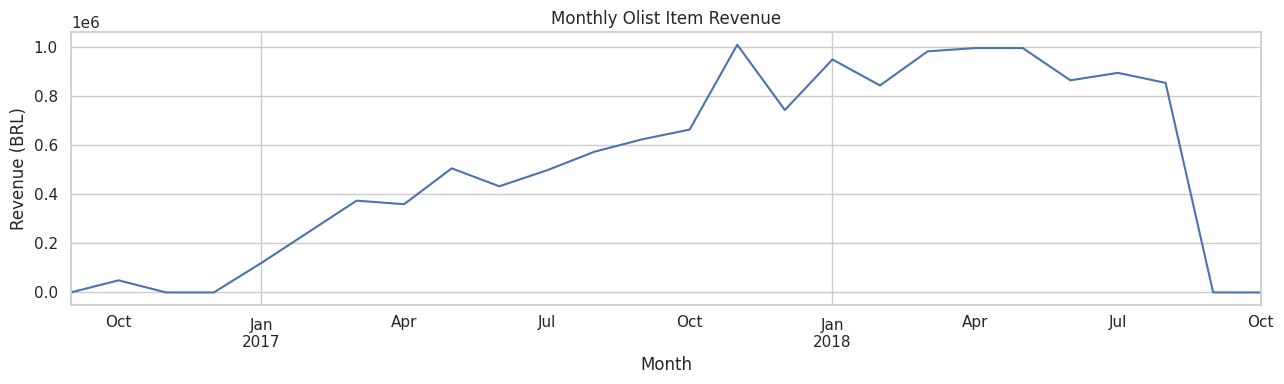

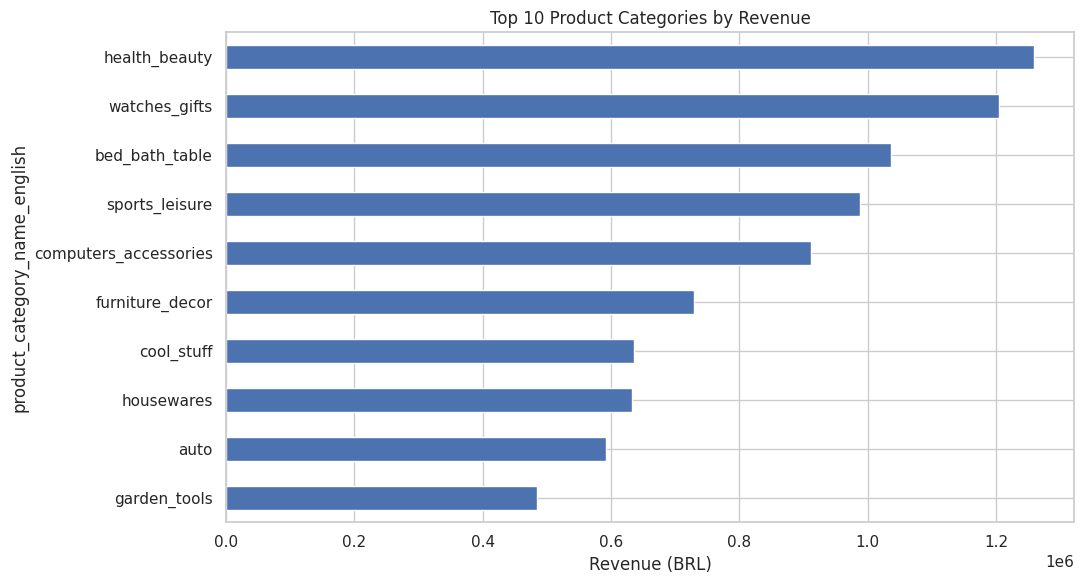

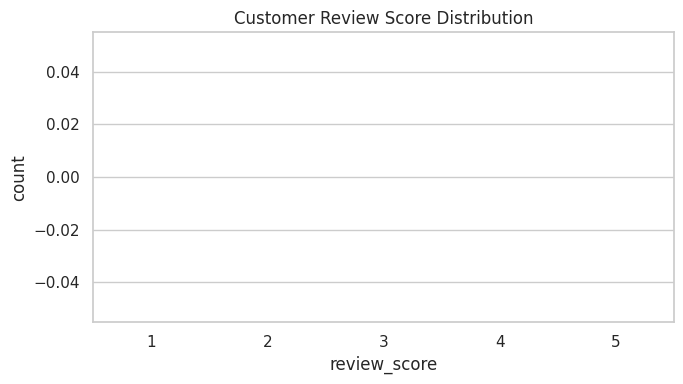

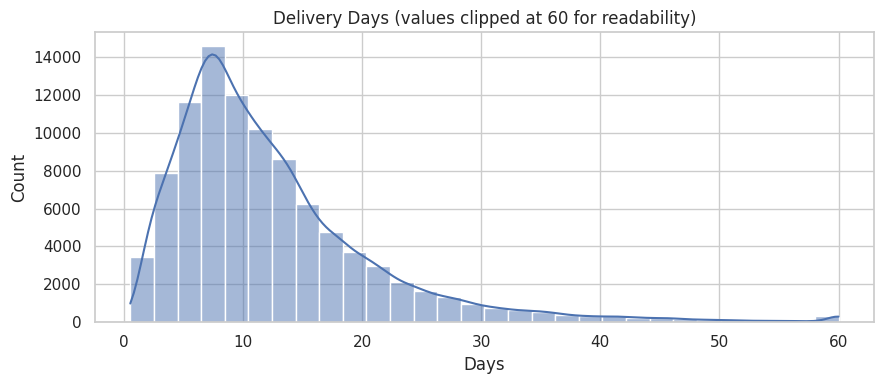

In [2]:
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

# Fallback: Reconstruct order_level and category_revenue if they are missing from the namespace
if 'order_level' not in globals() or 'category_revenue' not in globals():
    try:
        DATA_DIR = Path("/content/olist_data")
        def load_csv(filename: str) -> pd.DataFrame:
            path = DATA_DIR / filename
            if not path.exists():
                fallback_path = Path("/content") / filename
                if fallback_path.exists():
                    return pd.read_csv(fallback_path)
                raise FileNotFoundError(f"Missing file: {path}.")
            return pd.read_csv(path)

        customers = load_csv("olist_customers_dataset.csv").drop_duplicates()
        orders = load_csv("olist_orders_dataset.csv").drop_duplicates()
        items = load_csv("olist_order_items_dataset.csv").drop_duplicates()
        payments = load_csv("olist_order_payments_dataset.csv").drop_duplicates()
        reviews = load_csv("olist_order_reviews_dataset.csv").drop_duplicates()
        products = load_csv("olist_products_dataset.csv").drop_duplicates()
        category_translation = load_csv("product_category_name_translation.csv").drop_duplicates()

        date_cols = [
            "order_purchase_timestamp", "order_approved_at",
            "order_delivered_carrier_date", "order_delivered_customer_date",
            "order_estimated_delivery_date"
        ]
        for col in date_cols:
            orders[col] = pd.to_datetime(orders[col], errors="coerce")

        item_agg = items.groupby("order_id").agg(
            item_revenue=("price", "sum"),
            freight_value=("freight_value", "sum"),
            item_count=("order_item_id", "count"),
            unique_products=("product_id", "nunique")
        ).reset_index()

        payment_agg = payments.groupby("order_id").agg(
            payment_value=("payment_value", "sum"),
            payment_installments=("payment_installments", "max")
        ).reset_index()

        review_agg = reviews.groupby("order_id").agg(
            review_score=("review_score", "mean"),
            review_text=("review_comment_message", "first")
        ).reset_index()

        order_level = (
            orders.merge(customers, on="customer_id", how="left")
                  .merge(item_agg, on="order_id", how="left")
                  .merge(payment_agg, on="order_id", how="left")
                  .merge(review_agg, on="order_id", how="left")
        )
        order_level["order_revenue"] = order_level["item_revenue"].fillna(0)
        order_level["delivery_days"] = (
            order_level["order_delivered_customer_date"] -
            order_level["order_purchase_timestamp"]
        ).dt.total_seconds() / 86400

        products["product_category_name"] = products["product_category_name"].fillna("unknown")
        products = products.merge(category_translation, on="product_category_name", how="left")
        products["product_category_name_english"] = products[
            "product_category_name_english"
        ].fillna(products["product_category_name"])

        product_lookup = products[["product_id", "product_category_name_english"]].drop_duplicates("product_id")
        item_level = items.merge(product_lookup, on="product_id", how="left")

        category_revenue = (
            item_level.groupby("product_category_name_english")["price"]
            .sum().sort_values(ascending=False).head(10)
        )
    except Exception as e:
        raise NameError(f"Variable reconstruction failed. Please execute data ingestion cells: {e}")

sns.set_theme(style="whitegrid")

# Monthly revenue
monthly_revenue = (
    order_level.dropna(subset=["order_purchase_timestamp"])
    .set_index("order_purchase_timestamp")
    .resample("MS")["order_revenue"].sum()
)

plt.figure(figsize=(13, 4))
monthly_revenue.plot()
plt.title("Monthly Olist Item Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (BRL)")
plt.tight_layout()
plt.show()

# Top product categories
plt.figure(figsize=(11, 6))
category_revenue.sort_values().plot(kind="barh")
plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Revenue (BRL)")
plt.tight_layout()
plt.show()

# Review distribution
plt.figure(figsize=(7, 4))
sns.countplot(data=order_level, x="review_score", order=[1, 2, 3, 4, 5])
plt.title("Customer Review Score Distribution")
plt.tight_layout()
plt.show()

# Delivery time distribution
plt.figure(figsize=(9, 4))
sns.histplot(order_level["delivery_days"].dropna().clip(upper=60), bins=30, kde=True)
plt.title("Delivery Days (values clipped at 60 for readability)")
plt.xlabel("Days")
plt.tight_layout()
plt.show()

## 10. Supervised learning — predict late delivery

In [12]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

RANDOM_STATE = 42
DATA_DIR = Path("/content/olist_data")

if 'order_level' not in globals():
    try:
        def load_csv(filename: str) -> pd.DataFrame:
            path = DATA_DIR / filename
            if not path.exists():
                fallback_path = Path("/content") / filename
                if fallback_path.exists():
                    return pd.read_csv(fallback_path)
                raise FileNotFoundError(f"Missing file: {path}.")
            return pd.read_csv(path)

        customers = load_csv("olist_customers_dataset.csv").drop_duplicates()
        orders = load_csv("olist_orders_dataset.csv").drop_duplicates()
        items = load_csv("olist_order_items_dataset.csv").drop_duplicates()
        payments = load_csv("olist_order_payments_dataset.csv").drop_duplicates()
        reviews = load_csv("olist_order_reviews_dataset.csv").drop_duplicates()

        date_cols = [
            "order_purchase_timestamp", "order_approved_at",
            "order_delivered_carrier_date", "order_delivered_customer_date",
            "order_estimated_delivery_date"
        ]
        for col in date_cols:
            orders[col] = pd.to_datetime(orders[col], errors="coerce")

        item_agg = items.groupby("order_id").agg(
            item_revenue=("price", "sum"),
            freight_value=("freight_value", "sum"),
            item_count=("order_item_id", "count"),
            unique_products=("product_id", "nunique")
        ).reset_index()

        payment_agg = payments.groupby("order_id").agg(
            payment_value=("payment_value", "sum"),
            payment_installments=("payment_installments", "max")
        ).reset_index()

        review_agg = reviews.groupby("order_id").agg(
            review_score=("review_score", "mean"),
            review_text=("review_comment_message", "first")
        ).reset_index()

        order_level = (
            orders.merge(customers, on="customer_id", how="left")
                  .merge(item_agg, on="order_id", how="left")
                  .merge(payment_agg, on="order_id", how="left")
                  .merge(review_agg, on="order_id", how="left")
        )
        order_level["order_revenue"] = order_level["item_revenue"].fillna(0)
        order_level["purchase_month"] = order_level["order_purchase_timestamp"].dt.month
        order_level["purchase_dayofweek"] = order_level["order_purchase_timestamp"].dt.dayofweek
        order_level["purchase_hour"] = order_level["order_purchase_timestamp"].dt.hour
        order_level["is_delivered"] = (order_level["order_status"] == "delivered").astype(int)
        order_level["late_delivery"] = np.where(
            order_level["is_delivered"].eq(1)
            & order_level["order_delivered_customer_date"].notna()
            & order_level["order_estimated_delivery_date"].notna(),
            (order_level["order_delivered_customer_date"] >
             order_level["order_estimated_delivery_date"]).astype(float),
            np.nan
        )
    except Exception as e:
        raise NameError(f"The variable 'order_level' was not defined and auto-recovery failed: {e}.")

# Only delivered orders with a known target are eligible.
ml = order_level.dropna(subset=["late_delivery"]).copy()
ml["late_delivery"] = ml["late_delivery"].astype(int)

# Optimized: Exclude 'customer_city' to prevent massive sparse expansion
feature_cols = [
    "order_revenue", "freight_value", "item_count",
    "unique_products", "payment_value", "payment_installments",
    "purchase_month", "purchase_dayofweek", "purchase_hour",
    "customer_state"
]
feature_cols = [c for c in feature_cols if c in ml.columns]

X = ml[feature_cols].copy()
y = ml["late_delivery"].copy()

numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocess = ColumnTransformer([
    ("num", numeric_pipe, numeric_cols),
    ("cat", categorical_pipe, categorical_cols)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

# Optimized n_estimators from 250 to 100 for fast training
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

trained_models = {}
metric_rows = []

for name, estimator in models.items():
    pipe = Pipeline([("preprocess", preprocess), ("model", estimator)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    trained_models[name] = pipe
    metric_rows.append({
        "model": name,
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0)
    })

classification_metrics = pd.DataFrame(metric_rows).sort_values("f1", ascending=False)
display(classification_metrics)

,model,accuracy,precision,recall,f1
0,Logistic Regression,0.677620,0.125141,0.496486,0.199897
1,Random Forest,0.912563,0.344388,0.086262,0.137966


## 11. XGBoost Late Delivery Prediction

In [13]:
!pip install xgboost
from xgboost import XGBClassifier
xgb_model = Pipeline([
    ("preprocess", preprocess),
    ("model", XGBClassifier(
        n_estimators=300,
        max_depth=8,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        eval_metric="logloss"
    ))
])

xgb_model.fit(X_train, y_train)

xgb_pred = xgb_model.predict(X_test)

print(classification_report(y_test, xgb_pred))

              precision    recall  f1-score   support

           0       0.92      1.00      0.96     17729
           1       0.47      0.02      0.03      1565

    accuracy                           0.92     19294
   macro avg       0.70      0.51      0.49     19294
weighted avg       0.88      0.92      0.88     19294



## 12. Feature Importance

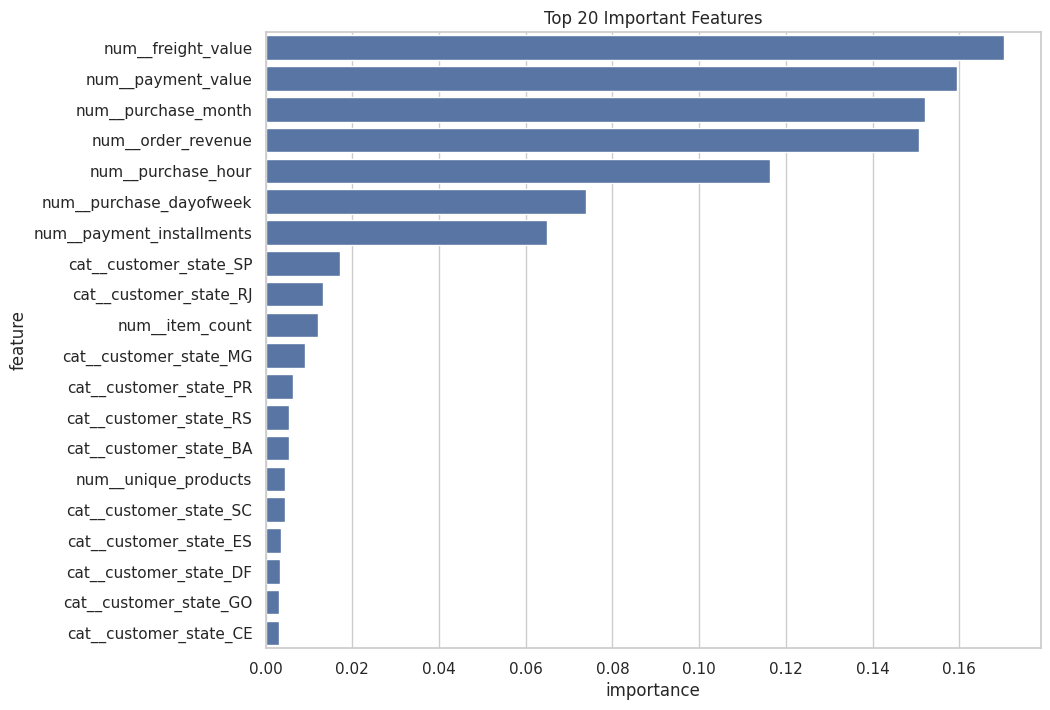

In [14]:
rf = trained_models["Random Forest"]

feature_names = rf.named_steps[
    "preprocess"
].get_feature_names_out()

importances = rf.named_steps[
    "model"
].feature_importances_

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
})

importance_df = importance_df.sort_values(
    "importance",
    ascending=False
)

plt.figure(figsize=(10,8))
sns.barplot(
    x="importance",
    y="feature",
    data=importance_df.head(20)
)

plt.title("Top 20 Important Features")
plt.show()

## 13.SHAP Explainability

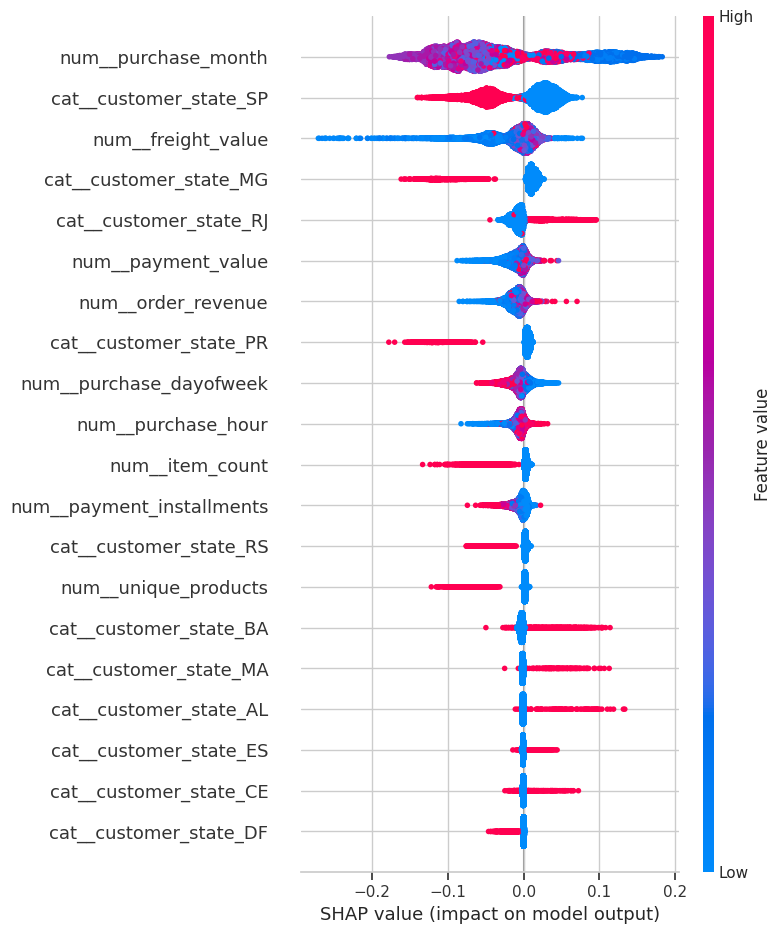

In [5]:
!pip install -q shap
import shap
import scipy.sparse
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

RANDOM_STATE = 42
DATA_DIR = Path("/content/olist_data")

# Fallback: Automatically reconstruct X_test, trained_models, and feature_names if missing
if 'trained_models' not in globals() or 'X_test' not in globals() or 'feature_names' not in globals():
    try:
        def load_csv(filename: str) -> pd.DataFrame:
            path = DATA_DIR / filename
            if not path.exists():
                fallback_path = Path("/content") / filename
                if fallback_path.exists():
                    return pd.read_csv(fallback_path)
                raise FileNotFoundError(f"Missing file: {path}.")
            return pd.read_csv(path)

        customers = load_csv("olist_customers_dataset.csv").drop_duplicates()
        orders = load_csv("olist_orders_dataset.csv").drop_duplicates()
        items = load_csv("olist_order_items_dataset.csv").drop_duplicates()
        payments = load_csv("olist_order_payments_dataset.csv").drop_duplicates()
        reviews = load_csv("olist_order_reviews_dataset.csv").drop_duplicates()

        date_cols = [
            "order_purchase_timestamp", "order_approved_at",
            "order_delivered_carrier_date", "order_delivered_customer_date",
            "order_estimated_delivery_date"
        ]
        for col in date_cols:
            orders[col] = pd.to_datetime(orders[col], errors="coerce")

        item_agg = items.groupby("order_id").agg(
            item_revenue=("price", "sum"),
            freight_value=("freight_value", "sum"),
            item_count=("order_item_id", "count"),
            unique_products=("product_id", "nunique")
        ).reset_index()

        payment_agg = payments.groupby("order_id").agg(
            payment_value=("payment_value", "sum"),
            payment_installments=("payment_installments", "max")
        ).reset_index()

        review_agg = reviews.groupby("order_id").agg(
            review_score=("review_score", "mean"),
            review_text=("review_comment_message", "first")
        ).reset_index()

        order_level = (
            orders.merge(customers, on="customer_id", how="left")
                  .merge(item_agg, on="order_id", how="left")
                  .merge(payment_agg, on="order_id", how="left")
                  .merge(review_agg, on="order_id", how="left")
        )
        order_level["order_revenue"] = order_level["item_revenue"].fillna(0)
        order_level["purchase_month"] = order_level["order_purchase_timestamp"].dt.month
        order_level["purchase_dayofweek"] = order_level["order_purchase_timestamp"].dt.dayofweek
        order_level["purchase_hour"] = order_level["order_purchase_timestamp"].dt.hour
        order_level["is_delivered"] = (order_level["order_status"] == "delivered").astype(int)
        order_level["late_delivery"] = np.where(
            order_level["is_delivered"].eq(1)
            & order_level["order_delivered_customer_date"].notna()
            & order_level["order_estimated_delivery_date"].notna(),
            (order_level["order_delivered_customer_date"] >
             order_level["order_estimated_delivery_date"]).astype(float),
            np.nan
        )

        ml = order_level.dropna(subset=["late_delivery"]).copy()
        ml["late_delivery"] = ml["late_delivery"].astype(int)

        feature_cols = [
            "order_revenue", "freight_value", "item_count",
            "unique_products", "payment_value", "payment_installments",
            "purchase_month", "purchase_dayofweek", "purchase_hour",
            "customer_state"
        ]
        feature_cols = [c for c in feature_cols if c in ml.columns]

        X = ml[feature_cols].copy()
        y = ml["late_delivery"].copy()

        numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
        categorical_cols = X.select_dtypes(exclude=np.number).columns.tolist()

        numeric_pipe = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ])
        categorical_pipe = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ])
        preprocess = ColumnTransformer([
            ("num", numeric_pipe, numeric_cols),
            ("cat", categorical_pipe, categorical_cols)
        ])

        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
        )

        # Train a light, fast Random Forest for SHAP explainability
        rf_pipe = Pipeline([
            ("preprocess", preprocess),
            ("model", RandomForestClassifier(
                n_estimators=50,
                max_depth=12,
                min_samples_leaf=2,
                class_weight="balanced",
                random_state=RANDOM_STATE,
                n_jobs=-1
            ))
        ])
        rf_pipe.fit(X_train, y_train)
        trained_models = {"Random Forest": rf_pipe}
        feature_names = preprocess.get_feature_names_out()
    except Exception as e:
        raise NameError(f"Variable recovery failed: {e}. Please run the classification training cells first.")

rf_model = trained_models["Random Forest"]

X_transformed = rf_model.named_steps[
    "preprocess"
].transform(X_test)

# Safely convert to a dense float array if it's a sparse matrix
if scipy.sparse.issparse(X_transformed):
    X_transformed_dense = X_transformed.toarray().astype(float)
else:
    X_transformed_dense = X_transformed.astype(float)

explainer = shap.TreeExplainer(
    rf_model.named_steps["model"]
)

shap_values = explainer.shap_values(
    X_transformed_dense
)

# For binary classification, slice for Class 1 (late) if output has classes dimension
if isinstance(shap_values, list):
    shap_to_plot = shap_values[1]
elif len(shap_values.shape) == 3:
    shap_to_plot = shap_values[:, :, 1]
else:
    shap_to_plot = shap_values

shap.summary_plot(
    shap_to_plot,
    X_transformed_dense,
    feature_names=feature_names
)

## 14. Delivery Time Regression (CatBoost Regression)

In [1]:
# =====================================
#  CatBoost Regression
# =====================================
!pip install -q catboost
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from catboost import CatBoostRegressor

RANDOM_STATE = 42
DATA_DIR = Path("/content/olist_data")

# Fallback: If run out-of-order, attempt to restore missing variables
if 'order_level' not in globals():
    try:
        def load_csv(filename: str) -> pd.DataFrame:
            path = DATA_DIR / filename
            if not path.exists():
                fallback_path = Path("/content") / filename
                if fallback_path.exists():
                    return pd.read_csv(fallback_path)
                raise FileNotFoundError(f"Missing file: {path}.")
            return pd.read_csv(path)

        customers = load_csv("olist_customers_dataset.csv").drop_duplicates()
        orders = load_csv("olist_orders_dataset.csv").drop_duplicates()
        items = load_csv("olist_order_items_dataset.csv").drop_duplicates()
        payments = load_csv("olist_order_payments_dataset.csv").drop_duplicates()
        reviews = load_csv("olist_order_reviews_dataset.csv").drop_duplicates()

        date_cols = [
            "order_purchase_timestamp", "order_approved_at",
            "order_delivered_carrier_date", "order_delivered_customer_date",
            "order_estimated_delivery_date"
        ]
        for col in date_cols:
            orders[col] = pd.to_datetime(orders[col], errors="coerce")

        item_agg = items.groupby("order_id").agg(
            item_revenue=("price", "sum"),
            freight_value=("freight_value", "sum"),
            item_count=("order_item_id", "count"),
            unique_products=("product_id", "nunique")
        ).reset_index()

        payment_agg = payments.groupby("order_id").agg(
            payment_value=("payment_value", "sum"),
            payment_installments=("payment_installments", "max")
        ).reset_index()

        review_agg = reviews.groupby("order_id").agg(
            review_score=("review_score", "mean"),
            review_text=("review_comment_message", "first")
        ).reset_index()

        order_level = (
            orders.merge(customers, on="customer_id", how="left")
                  .merge(item_agg, on="order_id", how="left")
                  .merge(payment_agg, on="order_id", how="left")
                  .merge(review_agg, on="order_id", how="left")
        )
        order_level["order_revenue"] = order_level["item_revenue"].fillna(0)
        order_level["purchase_month"] = order_level["order_purchase_timestamp"].dt.month
        order_level["purchase_dayofweek"] = order_level["order_purchase_timestamp"].dt.dayofweek
        order_level["purchase_hour"] = order_level["order_purchase_timestamp"].dt.hour
        order_level["is_delivered"] = (order_level["order_status"] == "delivered").astype(int)
        order_level["delivery_days"] = (
            order_level["order_delivered_customer_date"] -
            order_level["order_purchase_timestamp"]
        ).dt.total_seconds() / 86400
        order_level["late_delivery"] = np.where(
            order_level["is_delivered"].eq(1)
            & order_level["order_delivered_customer_date"].notna()
            & order_level["order_estimated_delivery_date"].notna(),
            (order_level["order_delivered_customer_date"] >
             order_level["order_estimated_delivery_date"]).astype(float),
            np.nan
        )
    except Exception as e:
        raise NameError(f"The variable 'order_level' was not defined and auto-recovery failed: {e}.")

# Ensure we have our regression dataset prepared
reg_data = order_level.dropna(subset=["delivery_days"]).copy()

Xr_cols = [
    "order_revenue", "freight_value", "item_count",
    "unique_products", "payment_value", "payment_installments",
    "purchase_month", "purchase_dayofweek", "purchase_hour",
    "customer_state"
]
Xr_cols = [col for col in Xr_cols if col in reg_data.columns]

Xr = reg_data[Xr_cols].copy()
yr = reg_data["delivery_days"].copy()

# Fill remaining numeric NaNs with median and categoricals with 'unknown'
for col in Xr.columns:
    if Xr[col].dtype == "object":
        Xr[col] = Xr[col].fillna("unknown").astype(str)
    else:
        Xr[col] = Xr[col].fillna(Xr[col].median())

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    Xr, yr, test_size=0.2, random_state=RANDOM_STATE
)

cat_features = [
    col for col in Xr.columns
    if Xr[col].dtype == "object"
]

cat_model = CatBoostRegressor(
    iterations=200,
    learning_rate=0.08,
    depth=6,
    random_state=RANDOM_STATE,
    verbose=0
)

cat_model.fit(
    Xr_train,
    yr_train,
    cat_features=cat_features
)

cat_pred = cat_model.predict(Xr_test)

print(
    "MAE:",
    mean_absolute_error(yr_test, cat_pred)
)

print(
    "RMSE:",
    np.sqrt(mean_squared_error(
        yr_test,
        cat_pred
    ))
)

print(
    "R2:",
    r2_score(
        yr_test,
        cat_pred
    )
)

MAE: 5.064723418319517
RMSE: 8.536976133784757
R2: 0.27143066849903286


## 15. Evaluation and tuning

Best baseline model: Logistic Regression
              precision    recall  f1-score   support

           0       0.94      0.69      0.80     17729
           1       0.13      0.50      0.20      1565

    accuracy                           0.68     19294
   macro avg       0.53      0.60      0.50     19294
weighted avg       0.87      0.68      0.75     19294



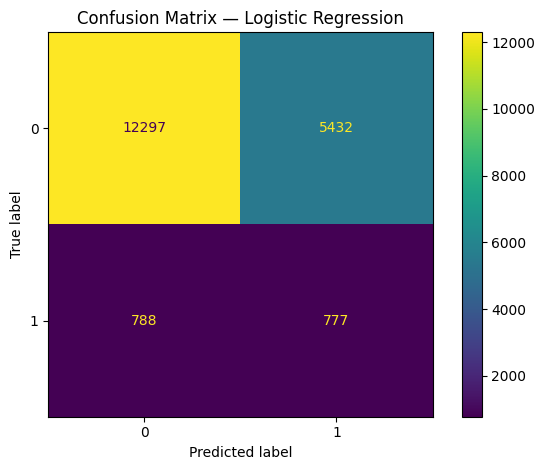

Fitting 3 folds for each of 8 candidates, totalling 24 fits


/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best parameters: {'model__max_depth': 15, 'model__min_samples_leaf': 3, 'model__n_estimators': 150}
Tuned test F1: 0.2753269784970073


In [2]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

RANDOM_STATE = 42
DATA_DIR = Path("/content/olist_data")

# Robust Fallback: Reconstruct training variables if they do not exist in the namespace
if 'classification_metrics' not in globals() or 'trained_models' not in globals() or 'X_test' not in globals():
    try:
        def load_csv(filename: str) -> pd.DataFrame:
            path = DATA_DIR / filename
            if not path.exists():
                fallback_path = Path("/content") / filename
                if fallback_path.exists():
                    return pd.read_csv(fallback_path)
                raise FileNotFoundError(f"Missing file: {path}.")
            return pd.read_csv(path)

        customers = load_csv("olist_customers_dataset.csv").drop_duplicates()
        orders = load_csv("olist_orders_dataset.csv").drop_duplicates()
        items = load_csv("olist_order_items_dataset.csv").drop_duplicates()
        payments = load_csv("olist_order_payments_dataset.csv").drop_duplicates()
        reviews = load_csv("olist_order_reviews_dataset.csv").drop_duplicates()

        date_cols = [
            "order_purchase_timestamp", "order_approved_at",
            "order_delivered_carrier_date", "order_delivered_customer_date",
            "order_estimated_delivery_date"
        ]
        for col in date_cols:
            orders[col] = pd.to_datetime(orders[col], errors="coerce")

        item_agg = items.groupby("order_id").agg(
            item_revenue=("price", "sum"),
            freight_value=("freight_value", "sum"),
            item_count=("order_item_id", "count"),
            unique_products=("product_id", "nunique")
        ).reset_index()

        payment_agg = payments.groupby("order_id").agg(
            payment_value=("payment_value", "sum"),
            payment_installments=("payment_installments", "max")
        ).reset_index()

        review_agg = reviews.groupby("order_id").agg(
            review_score=("review_score", "mean"),
            review_text=("review_comment_message", "first")
        ).reset_index()

        order_level = (
            orders.merge(customers, on="customer_id", how="left")
                  .merge(item_agg, on="order_id", how="left")
                  .merge(payment_agg, on="order_id", how="left")
                  .merge(review_agg, on="order_id", how="left")
        )
        order_level["order_revenue"] = order_level["item_revenue"].fillna(0)
        order_level["purchase_month"] = order_level["order_purchase_timestamp"].dt.month
        order_level["purchase_dayofweek"] = order_level["order_purchase_timestamp"].dt.dayofweek
        order_level["purchase_hour"] = order_level["order_purchase_timestamp"].dt.hour
        order_level["is_delivered"] = (order_level["order_status"] == "delivered").astype(int)
        order_level["late_delivery"] = np.where(
            order_level["is_delivered"].eq(1)
            & order_level["order_delivered_customer_date"].notna()
            & order_level["order_estimated_delivery_date"].notna(),
            (order_level["order_delivered_customer_date"] >
             order_level["order_estimated_delivery_date"]).astype(float),
            np.nan
        )

        ml = order_level.dropna(subset=["late_delivery"]).copy()
        ml["late_delivery"] = ml["late_delivery"].astype(int)

        feature_cols = [
            "order_revenue", "freight_value", "item_count",
            "unique_products", "payment_value", "payment_installments",
            "purchase_month", "purchase_dayofweek", "purchase_hour",
            "customer_state"
        ]
        feature_cols = [c for c in feature_cols if c in ml.columns]

        X = ml[feature_cols].copy()
        y = ml["late_delivery"].copy()

        numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
        categorical_cols = X.select_dtypes(exclude=np.number).columns.tolist()

        numeric_pipe = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ])
        categorical_pipe = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ])
        preprocess = ColumnTransformer([
            ("num", numeric_pipe, numeric_cols),
            ("cat", categorical_pipe, categorical_cols)
        ])

        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
        )

        models = {
            "Logistic Regression": LogisticRegression(
                max_iter=1000, class_weight="balanced"
            ),
            "Random Forest": RandomForestClassifier(
                n_estimators=100,
                min_samples_leaf=2,
                class_weight="balanced",
                random_state=RANDOM_STATE,
                n_jobs=-1
            )
        }

        trained_models = {}
        metric_rows = []

        for name, estimator in models.items():
            pipe = Pipeline([("preprocess", preprocess), ("model", estimator)])
            pipe.fit(X_train, y_train)
            pred = pipe.predict(X_test)
            trained_models[name] = pipe
            metric_rows.append({
                "model": name,
                "accuracy": accuracy_score(y_test, pred),
                "precision": precision_score(y_test, pred, zero_division=0),
                "recall": recall_score(y_test, pred, zero_division=0),
                "f1": f1_score(y_test, pred, zero_division=0)
            })

        classification_metrics = pd.DataFrame(metric_rows).sort_values("f1", ascending=False)
    except Exception as e:
        raise NameError(f"The variable 'classification_metrics' was missing and auto-recovery failed: {e}.")

best_name = classification_metrics.iloc[0]["model"]
best_model = trained_models[best_name]
best_pred = best_model.predict(X_test)

print("Best baseline model:", best_name)
print(classification_report(y_test, best_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, best_pred)
plt.title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()

# Tune Random Forest using a compact grid.
rf_pipeline = Pipeline([
    ("preprocess", preprocess),
    ("model", RandomForestClassifier(
        class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
    ))
])
param_grid = {
    "model__n_estimators": [150, 250],
    "model__max_depth": [None, 15],
    "model__min_samples_leaf": [1, 3]
}
grid = GridSearchCV(
    rf_pipeline, param_grid, cv=3,
    scoring="f1", n_jobs=-1, verbose=1
)
grid.fit(X_train, y_train)
tuned_model = grid.best_estimator_
tuned_pred = tuned_model.predict(X_test)
print("Best parameters:", grid.best_params_)
print("Tuned test F1:", f1_score(y_test, tuned_pred, zero_division=0))

## 16. Unsupervised learning — customer segmentation

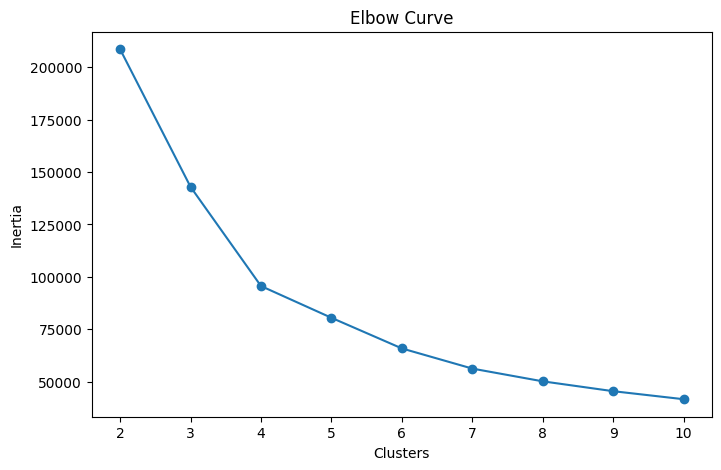

K=2  Score=0.734
K=3  Score=0.458
K=4  Score=0.490
K=5  Score=0.421
K=6  Score=0.439
K=7  Score=0.441
K=8  Score=0.448
K=9  Score=0.385
K=10  Score=0.393


,recency_days,frequency,monetary
segment,,,
0,438.76,1.00,112.79
1,178.38,1.00,113.19
2,269.21,2.12,239.42
3,289.96,1.02,1142.36


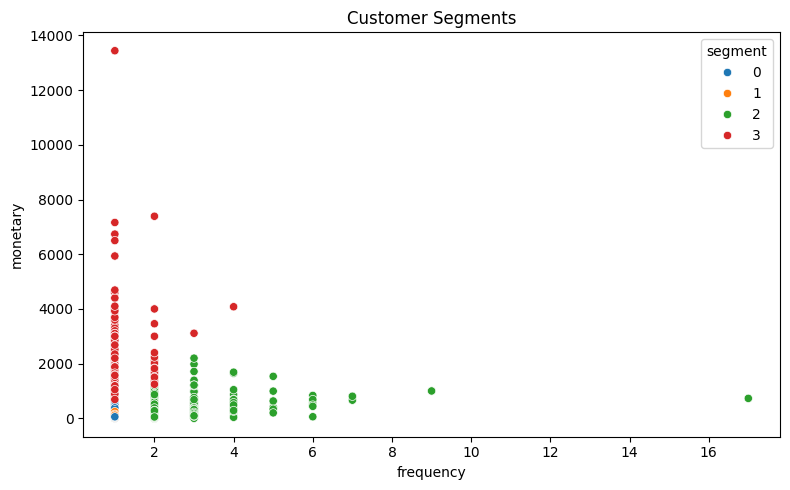

In [3]:
# Customer-level RFM-style features.
# This is descriptive segmentation over the full historical dataset, not a prospective prediction.
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
DATA_DIR = Path("/content/olist_data")

# Fallback: Reconstruct order_level if it does not exist in the active namespace
if 'order_level' not in globals():
    try:
        def load_csv(filename: str) -> pd.DataFrame:
            path = DATA_DIR / filename
            if not path.exists():
                fallback_path = Path("/content") / filename
                if fallback_path.exists():
                    return pd.read_csv(fallback_path)
                raise FileNotFoundError(f"Missing file: {path}.")
            return pd.read_csv(path)

        customers = load_csv("olist_customers_dataset.csv").drop_duplicates()
        orders = load_csv("olist_orders_dataset.csv").drop_duplicates()
        items = load_csv("olist_order_items_dataset.csv").drop_duplicates()
        payments = load_csv("olist_order_payments_dataset.csv").drop_duplicates()
        reviews = load_csv("olist_order_reviews_dataset.csv").drop_duplicates()

        date_cols = [
            "order_purchase_timestamp", "order_approved_at",
            "order_delivered_carrier_date", "order_delivered_customer_date",
            "order_estimated_delivery_date"
        ]
        for col in date_cols:
            orders[col] = pd.to_datetime(orders[col], errors="coerce")

        item_agg = items.groupby("order_id").agg(
            item_revenue=("price", "sum"),
            freight_value=("freight_value", "sum"),
            item_count=("order_item_id", "count"),
            unique_products=("product_id", "nunique")
        ).reset_index()

        payment_agg = payments.groupby("order_id").agg(
            payment_value=("payment_value", "sum"),
            payment_installments=("payment_installments", "max")
        ).reset_index()

        review_agg = reviews.groupby("order_id").agg(
            review_score=("review_score", "mean"),
            review_text=("review_comment_message", "first")
        ).reset_index()

        order_level = (
            orders.merge(customers, on="customer_id", how="left")
                  .merge(item_agg, on="order_id", how="left")
                  .merge(payment_agg, on="order_id", how="left")
                  .merge(review_agg, on="order_id", how="left")
        )
        order_level["order_revenue"] = order_level["item_revenue"].fillna(0)
    except Exception as e:
        raise NameError(f"The variable 'order_level' was not defined and auto-recovery failed: {e}.")

reference_date = order_level["order_purchase_timestamp"].max() + pd.Timedelta(days=1)
customer_features = (
    order_level.dropna(subset=["order_purchase_timestamp"])
    .groupby("customer_unique_id")
    .agg(
        last_purchase=("order_purchase_timestamp", "max"),
        frequency=("order_id", "nunique"),
        monetary=("order_revenue", "sum")
    )
    .reset_index()
)
customer_features["recency_days"] = (
    reference_date - customer_features["last_purchase"]
).dt.days

seg_cols = ["recency_days", "frequency", "monetary"]
seg_data = customer_features[seg_cols].replace([np.inf, -np.inf], np.nan)
seg_data = seg_data.fillna(seg_data.median())

seg_scaler = StandardScaler()
seg_scaled = seg_scaler.fit_transform(seg_data)
kmeans = KMeans(
    n_clusters=4
)
# =====================================
#  Elbow Method
# =====================================

inertia = []

for k in range(2,11):

    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    km.fit(seg_scaled)

    inertia.append(
        km.inertia_
    )

plt.figure(figsize=(8,5))

plt.plot(
    range(2,11),
    inertia,
    marker="o"
)

plt.title(
    "Elbow Curve"
)

plt.xlabel(
    "Clusters"
)

plt.ylabel(
    "Inertia"
)

plt.show()

# =====================================
#  Silhouette Analysis
# =====================================

from sklearn.metrics import silhouette_score

for k in range(2,11):

    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = km.fit_predict(
        seg_scaled
    )

    score = silhouette_score(
        seg_scaled,
        labels
    )

    print(
        f"K={k}  Score={score:.3f}"
    )

kmeans = KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=10)
customer_features["segment"] = kmeans.fit_predict(seg_scaled)

segment_profile = customer_features.groupby("segment")[seg_cols].mean().round(2)
display(segment_profile)

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=customer_features, x="frequency", y="monetary",
    hue="segment", palette="tab10"
)
plt.title("Customer Segments")
plt.tight_layout()
plt.show()

## 17. Time series forecasting — monthly revenue with SARIMA

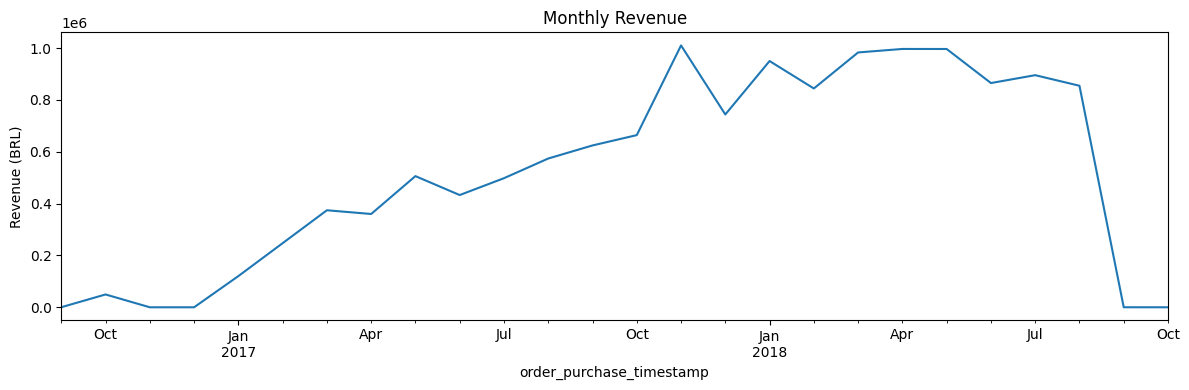

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


Forecast MAE: 443590.27709670115
Forecast RMSE: 628081.2588193048


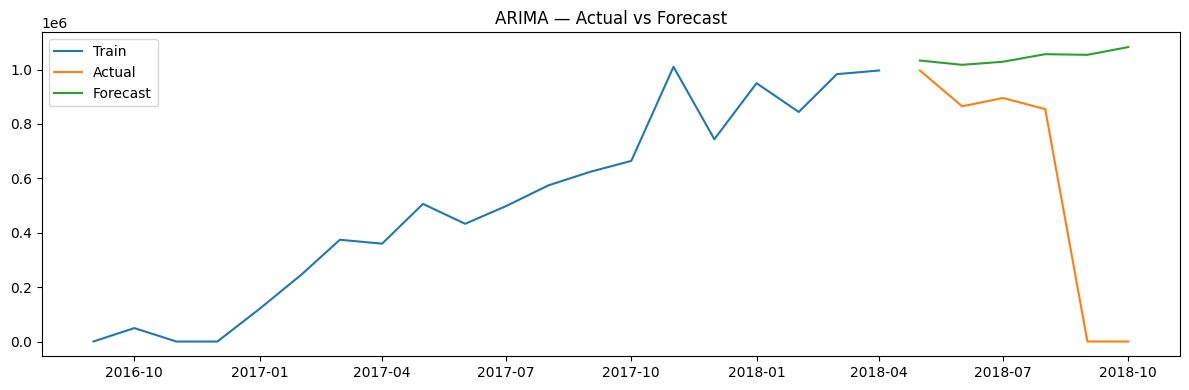

,forecast_revenue
2018-05-01,1.033341e+06
2018-06-01,1.017542e+06
2018-07-01,1.028836e+06
2018-08-01,1.056680e+06
2018-09-01,1.054278e+06
2018-10-01,1.082846e+06


In [4]:
# Monthly revenue series; chronological split prevents random time leakage.
monthly = (
    order_level.dropna(subset=["order_purchase_timestamp"])
    .set_index("order_purchase_timestamp")["order_revenue"]
    .resample("MS").sum()
)
monthly = monthly.asfreq("MS").fillna(0)

plt.figure(figsize=(12, 4))
monthly.plot()
plt.title("Monthly Revenue")
plt.ylabel("Revenue (BRL)")
plt.tight_layout()
plt.show()

if len(monthly) < 24:
    print("Warning: fewer than 24 monthly observations; forecasts may be unstable.")

split_at = max(1, int(len(monthly) * 0.8))
ts_train, ts_test = monthly.iloc[:split_at], monthly.iloc[split_at:]

# ARIMA(2,1,2) baseline. Compare orders / seasonal models for a stronger final study.
from statsmodels.tsa.statespace.sarimax import SARIMAX

sarima_fit = SARIMAX(
    ts_train,
    order=(1,1,1),
    seasonal_order=(1,1,1,12)
).fit()
ts_forecast = sarima_fit.forecast(steps=len(ts_test))

if len(ts_test):
    print("Forecast MAE:", mean_absolute_error(ts_test, ts_forecast))
    print("Forecast RMSE:", np.sqrt(mean_squared_error(ts_test, ts_forecast)))

plt.figure(figsize=(12, 4))
plt.plot(ts_train.index, ts_train, label="Train")
plt.plot(ts_test.index, ts_test, label="Actual")
if len(ts_test):
    plt.plot(ts_test.index, ts_forecast, label="Forecast")
plt.legend()
plt.title("ARIMA — Actual vs Forecast")
plt.tight_layout()
plt.show()

future_revenue = sarima_fit.forecast(steps=6)
display(future_revenue.rename("forecast_revenue").to_frame())


Segment Labels

In [6]:
segment_labels = {
    0: "VIP",
    1: "Regular",
    2: "At Risk",
    3: "New"
}

customer_features["segment_name"] = (
    customer_features["segment"]
    .map(segment_labels)
)

### 18. NLP — Portuguese review sentiment

In [8]:
import re
import nltk
nltk.download("stopwords")
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
import numpy as np

# Weak labels derived from review stars. This does not replace human-labelled sentiment data.
text_data = order_level.dropna(subset=["review_text", "review_score"]).copy()
text_data["review_text"] = text_data["review_text"].astype(str)
text_data = text_data[text_data["review_text"].str.strip().ne("")]
text_data["sentiment"] = np.select(
    [text_data["review_score"] <= 2, text_data["review_score"] == 3,
     text_data["review_score"] >= 4],
    ["negative", "neutral", "positive"],
    default="unknown"
)
text_data = text_data[text_data["sentiment"] != "unknown"]

pt_stopwords = set(stopwords.words("portuguese"))

def clean_portuguese_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-zà-ÿ\s]", " ", text)
    tokens = [w for w in text.split() if w not in pt_stopwords and len(w) > 2]
    return " ".join(tokens)

text_data["clean_text"] = text_data["review_text"].apply(clean_portuguese_text)
text_data = text_data[text_data["clean_text"].str.len() > 0]

X_text = text_data["clean_text"]
y_text = text_data["sentiment"]

Xtr, Xte, ytr, yte = train_test_split(
    X_text, y_text, test_size=0.2,
    random_state=RANDOM_STATE, stratify=y_text
)
tfidf = TfidfVectorizer(max_features=12000, ngram_range=(1, 2), min_df=2)
Xtr_vec = tfidf.fit_transform(Xtr)
Xte_vec = tfidf.transform(Xte)

nlp_model = LogisticRegression(
    max_iter=1200, class_weight="balanced"
)
nlp_model.fit(Xtr_vec, ytr)
nlp_pred = nlp_model.predict(Xte_vec)
print(classification_report(yte, nlp_pred, zero_division=0))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


              precision    recall  f1-score   support

    negative       0.77      0.79      0.78      2158
     neutral       0.23      0.40      0.29       704
    positive       0.95      0.84      0.89      5218

    accuracy                           0.79      8080
   macro avg       0.65      0.68      0.65      8080
weighted avg       0.84      0.79      0.81      8080



## 19. Deep learning — neural network for late-delivery classification

In [9]:
# TensorFlow model using numeric features only.
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from sklearn.utils.class_weight import compute_class_weight

deep_cols = [
    "order_revenue", "freight_value", "item_count",
    "unique_products", "payment_value", "payment_installments",
    "purchase_month", "purchase_dayofweek", "purchase_hour"
]
deep_cols = [c for c in deep_cols if c in ml.columns]
deep_frame = ml[deep_cols].copy()
deep_target = ml["late_delivery"].astype(int)

Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    deep_frame, deep_target, test_size=0.2,
    random_state=RANDOM_STATE, stratify=deep_target
)

deep_prep = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
Xd_train_scaled = deep_prep.fit_transform(Xd_train)
Xd_test_scaled = deep_prep.transform(Xd_test)

class_values = np.unique(yd_train)
class_weights_arr = compute_class_weight(
    class_weight="balanced", classes=class_values, y=yd_train
)
class_weights = dict(zip(class_values, class_weights_arr))

tf.keras.utils.set_random_seed(RANDOM_STATE)
nn_model = Sequential([
    Input(shape=(Xd_train_scaled.shape[1],)),
    Dense(64, activation="relu"),
    Dropout(0.25),
    Dense(32, activation="relu"),
    Dense(1, activation="sigmoid")
])
nn_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[tf.keras.metrics.AUC(name="auc"), "accuracy"]
)
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)
history = nn_model.fit(
    Xd_train_scaled, yd_train,
    validation_split=0.2, epochs=20, batch_size=128,
    class_weight=class_weights, callbacks=[early_stop],
    verbose=1
)
nn_prob = nn_model.predict(Xd_test_scaled, verbose=0).ravel()
nn_pred = (nn_prob >= 0.5).astype(int)
print(classification_report(yd_test, nn_pred, zero_division=0))


Epoch 1/20
483/483 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5112 - auc: 0.5658 - loss: 0.6898 - val_accuracy: 0.5525 - val_auc: 0.6041 - val_loss: 0.6860
Epoch 2/20
483/483 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5563 - auc: 0.6034 - loss: 0.6799 - val_accuracy: 0.5671 - val_auc: 0.6167 - val_loss: 0.6844
Epoch 3/20
483/483 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5724 - auc: 0.6138 - loss: 0.6762 - val_accuracy: 0.5676 - val_auc: 0.6211 - val_loss: 0.6760
Epoch 4/20
483/483 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5750 - auc: 0.6192 - loss: 0.6736 - val_accuracy: 0.5698 - val_auc: 0.6252 - val_loss: 0.6698
Epoch 5/20
483/483 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5792 - auc: 0.6288 - loss: 0.6699 - val_accuracy: 0.5724 - val_auc: 0.6269 - val_loss: 0.6643
Epoch 6/20
483/483 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5834 - auc: 0.6315 - loss: 0.6681 - val_accuracy: 0.5689 - val_auc: 0.6309 - val_loss: 0.6643
Epoch 7/20
483/483 ━━━━━━━━━━━━━━━━━━━━ 

## 20. Recommendation system — item-based collaborative filtering

In [12]:
# Build a sparse customer-product interaction matrix.
# Limit to products with enough interactions to keep similarity computation manageable.
from scipy.sparse import csr_matrix
from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import cosine_similarity

interactions = items[["order_id", "product_id"]].merge(
    orders[["order_id", "customer_id"]], on="order_id", how="inner"
).merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id", how="left"
).dropna(subset=["customer_unique_id", "product_id"])

popular_products = interactions["product_id"].value_counts()
eligible_products = popular_products[popular_products >= 5].index
interactions = interactions[interactions["product_id"].isin(eligible_products)]

# Use a bounded product set for a practical Colab demonstration.
top_product_ids = popular_products.loc[
    popular_products.index.intersection(eligible_products)
].head(1500).index
interactions = interactions[interactions["product_id"].isin(top_product_ids)]

customer_codes, customer_uniques = pd.factorize(interactions["customer_unique_id"])
product_codes, product_uniques = pd.factorize(interactions["product_id"])

matrix = csr_matrix(
    (np.ones(len(interactions)), (customer_codes, product_codes)),
    shape=(len(customer_uniques), len(product_uniques))
)

# Item-item cosine similarity.
item_similarity = cosine_similarity(matrix.T, dense_output=True)
item_similarity_df = pd.DataFrame(
    item_similarity, index=product_uniques, columns=product_uniques
)

def recommend_similar_products(product_id, top_n=5):
    if product_id not in item_similarity_df.columns:
        return pd.Series(dtype=float, name="similarity")
    return (
        item_similarity_df[product_id]
        .drop(index=product_id)
        .sort_values(ascending=False)
        .head(top_n)
        .rename("similarity")
    )

if len(product_uniques):
    example_product = product_uniques[0]
    print("Example product:", example_product)
    display(recommend_similar_products(example_product, 5).to_frame())

Example product: ac6c3623068f30de03045865e4e10089


,similarity
143c616ec3fe0cb065c3805cf9bd812e,0.0
d63c1011f49d98b976c352955b1c4bea,0.0
99a4788cb24856965c36a24e339b6058,0.0
368c6c730842d78016ad823897a372db,0.0
4fa33915031a8cde03dd0d3e8fb27f01,0.0


## 21. Big Data — PySpark demonstration

In [15]:
# Run after the Pandas sections. Local[*] uses available local CPU cores.
from pyspark.sql import SparkSession
from pyspark.sql.functions import count, sum as spark_sum, col
from pathlib import Path

# Re-define required directories and files dictionary locally to ensure self-sufficiency
DATA_DIR = Path("/content/olist_data")
FILES = {
    "customers": "olist_customers_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "category_translation": "product_category_name_translation.csv",
}

spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("OlistEcommerceAnalytics")
    .getOrCreate()
)

# Helper to find correct path dynamically
def get_spark_path(filename: str) -> str:
    path = DATA_DIR / filename
    if not path.exists():
        fallback_path = Path("/content") / filename
        if fallback_path.exists():
            return str(fallback_path)
    return str(path)

spark_orders = spark.read.csv(
    get_spark_path(FILES["orders"]),
    header=True, inferSchema=True
)
spark_items = spark.read.csv(
    get_spark_path(FILES["items"]),
    header=True, inferSchema=True
)
spark_customers = spark.read.csv(
    get_spark_path(FILES["customers"]),
    header=True, inferSchema=True
)

print("Spark orders:", spark_orders.count())
spark_customers.groupBy("customer_state").agg(
    count("*").alias("customer_rows")
).orderBy(col("customer_rows").desc()).show(10)

spark_items.groupBy("product_id").agg(
    spark_sum("price").alias("item_revenue")
).orderBy(col("item_revenue").desc()).show(10)

spark.stop()

Spark orders: 99441
+--------------+-------------+
|customer_state|customer_rows|
+--------------+-------------+
|            SP|        41746|
|            RJ|        12852|
|            MG|        11635|
|            RS|         5466|
|            PR|         5045|
|            SC|         3637|
|            BA|         3380|
|            DF|         2140|
|            ES|         2033|
|            GO|         2020|
+--------------+-------------+
only showing top 10 rows
+--------------------+------------------+
|          product_id|      item_revenue|
+--------------------+------------------+
|bb50f2e236e5eea01...|           63885.0|
|6cdd53843498f9289...| 54730.20000000005|
|d6160fb7873f18409...|48899.340000000004|
|d1c427060a0f73f6b...| 47214.51000000006|
|99a4788cb24856965...|43025.560000000085|
|3dd2a17168ec895c7...| 41082.60000000005|
|25c38557cf793876c...| 38907.32000000001|
|5f504b3a1c75b73d6...|37733.899999999994|
|53b36df67ebb7c415...| 37683.42000000001|
|aca2eb7d00ea1a7b

## 22. **Streamlit development** — interactive web application
Streamlit turns the project outputs and trained model into a small interactive web app.

In [17]:
from pathlib import Path
import os

# Define output directory robustly
OUTPUT_DIR = Path("/content/olist_outputs")
MODEL_DIR = OUTPUT_DIR / "models"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save the Streamlit app and requirements file into the project output folder.
# Run this cell after completing the model export section.

streamlit_app_code = r'''from pathlib import Path
import joblib
import pandas as pd
import streamlit as st

st.set_page_config(page_title="Olist Data Science Dashboard", page_icon="🛒", layout="wide")

# Expected folder structure:
# app.py
# olist_outputs/
#   olist_sales_powerbi.csv
#   customer_segments.csv
#   monthly_revenue.csv
#   future_revenue_forecast.csv (optional)
#   review_sentiment_results.csv (optional)
#   models/late_delivery_model.joblib

ROOT = Path(__file__).resolve().parent
OUTPUT_DIR = ROOT / "olist_outputs"
MODEL_DIR = OUTPUT_DIR / "models"

@st.cache_data
def load_csv(filename):
    path = OUTPUT_DIR / filename
    return pd.read_csv(path) if path.exists() else pd.DataFrame()

@st.cache_resource
def load_model():
    path = MODEL_DIR / "late_delivery_model.joblib"
    return joblib.load(path) if path.exists() else None

sales = load_csv("olist_sales_powerbi.csv")
segments = load_csv("customer_segments.csv")
monthly = load_csv("monthly_revenue.csv")
forecast = load_csv("future_revenue_forecast.csv")
sentiment = load_csv("review_sentiment_results.csv")

st.title("Olist Brazilian E-Commerce — Data Science App")
st.caption("Interactive Streamlit application built from the Olist final project outputs.")

if sales.empty:
    st.error("Sales data not found. Place olist_sales_powerbi.csv inside the olist_outputs folder.")
    st.stop()

# Parse dates and apply a date filter
if "order_purchase_timestamp" in sales.columns:
    sales["order_purchase_timestamp"] = pd.to_datetime(
        sales["order_purchase_timestamp"], errors="coerce"
    )

with st.sidebar:
    st.header("Dashboard filters")
    if "customer_state" in sales.columns:
        states = sorted(sales["customer_state"].dropna().astype(str).unique())
        selected_states = st.multiselect("Customer state", states, default=states)
        if selected_states:
            sales_view = sales[sales["customer_state"].astype(str).isin(selected_states)].copy()
        else:
            sales_view = sales.iloc[0:0].copy()
    else:
        sales_view = sales.copy()

    if "order_purchase_timestamp" in sales_view.columns:
        valid_dates = sales_view["order_purchase_timestamp"].dropna()
        if not valid_dates.empty:
            start_date = valid_dates.min().date()
            end_date = valid_dates.max().date()
            date_range = st.date_input("Purchase date range", value=(start_date, end_date))
            if isinstance(date_range, tuple) and len(date_range) == 2:
                sales_view = sales_view[
                    sales_view["order_purchase_timestamp"].dt.date.between(
                        date_range[0], date_range[1]
                    )
                ]

revenue_col = "order_revenue" if "order_revenue" in sales_view.columns else None
orders_count = sales_view["order_id"].nunique() if "order_id" in sales_view.columns else len(sales_view)
revenue = sales_view[revenue_col].sum() if revenue_col else 0
aov = revenue / orders_count if orders_count else 0
customers = sales_view["customer_unique_id"].nunique() if "customer_unique_id" in sales_view.columns else 0

c1, c2, c3, c4 = st.columns(4)
c1.metric("Total orders", f"{orders_count:,}")
c2.metric("Item revenue", f"R$ {revenue:,.2f}")
c3.metric("Average order value", f"R$ {aov:,.2f}")
c4.metric("Unique customers", f"{customers:,}")

tab1, tab2, tab3, tab4 = st.tabs(
    ["Sales analysis", "Customer segments", "Delivery prediction", "Review sentiment"]
)

with tab1:
    st.subheader("Sales overview")
    if revenue_col and "order_purchase_timestamp" in sales_view.columns:
        trend = (sales_view.dropna(subset=["order_purchase_timestamp"])
                 .set_index("order_purchase_timestamp")
                 .resample("MS")[revenue_col].sum())
        st.line_chart(trend)
    if "customer_state" in sales_view.columns and revenue_col:
        state_sales = (sales_view.groupby("customer_state", as_index=False)[revenue_col]
                       .sum().sort_values(revenue_col, ascending=False).head(10))
        st.write("Top 10 states by revenue")
        st.bar_chart(state_sales.set_index("customer_state"))
    st.dataframe(sales_view.head(500), use_container_width=True)

    if not monthly.empty:
        st.subheader("Monthly revenue series")
        st.dataframe(monthly, use_container_width=True)
    if not forecast.empty:
        st.subheader("Future revenue forecast")
        st.dataframe(forecast, use_container_width=True)

with tab2:
    st.subheader("Customer segmentation")
    if segments.empty:
        st.info("customer_segments.csv was not found in olist_outputs.")
    else:
        st.write("Customer-level RFM-style features and cluster assignments.")
        st.dataframe(segments.head(500), use_container_width=True)
        cluster_col = next((c for c in ["cluster", "customer_cluster", "segment"] if c in segments.columns), None)
        if cluster_col:
            st.bar_chart(segments[cluster_col].value_counts().sort_index())

with tab3:
    st.subheader("Late delivery prediction")
    model = load_model()
    if model is None:
        st.warning("Model file not found. Run the model-training and export cells in the notebook first.")
    else:
        st.write("Enter order details to estimate whether an order may be delivered late.")
        with st.form("prediction_form"):
            a, b, c = st.columns(3)
            with a:
                order_revenue = st.number_input("Order revenue (BRL)", min_value=0.0, value=150.0)
                freight_value = st.number_input("Freight value (BRL)", min_value=0.0, value=20.0)
                item_count = st.number_input("Number of items", min_value=1, value=1, step=1)
                unique_products = st.number_input("Unique products", min_value=1, value=1, step=1)
            with b:
                payment_value = st.number_input("Payment value (BRL)", min_value=0.0, value=170.0)
                payment_installments = st.number_input("Payment installments", min_value=1, value=1, step=1)
                purchase_month = st.selectbox("Purchase month", list(range(1, 13)), index=5)
                purchase_dayofweek = st.selectbox("Purchase day of week (Mon=0)", list(range(7)))
            with c:
                purchase_hour = st.slider("Purchase hour", 0, 23, 12)
                customer_state = st.text_input("Customer state code", value="SP").upper()
                customer_city = st.text_input("Customer city", value="sao paulo").lower()
            submitted = st.form_submit_button("Predict delivery status")

        if submitted:
            input_df = pd.DataFrame([{
                "order_revenue": order_revenue,
                "freight_value": freight_value,
                "item_count": item_count,
                "unique_products": unique_products,
                "payment_value": payment_value,
                "payment_installments": payment_installments,
                "purchase_month": purchase_month,
                "purchase_dayofweek": purchase_dayofweek,
                "purchase_hour": purchase_hour,
                "customer_state": customer_state,
                "customer_city": customer_city
            }])
            try:
                prediction = int(model.predict(input_df)[0])
                if hasattr(model, "predict_proba"):
                    probability = float(model.predict_proba(input_df)[0][1])
                    st.metric("Estimated late-delivery probability", f"{probability:.1%}")
                if prediction == 1:
                    st.warning("Model prediction: Late delivery")
                else:
                    st.success("Model prediction: On-time delivery")
                st.caption("This is a model estimate, not a guaranteed delivery date.")
            except Exception as exc:
                st.error(f"Prediction could not be generated: {exc}")

with tab4:
    st.subheader("Customer review sentiment")
    if sentiment.empty:
        st.info("review_sentiment_results.csv was not found in olist_outputs.")
    else:
        st.write("Held-out review sentiment predictions from the NLP model.")
        if "predicted_sentiment" in sentiment.columns:
            st.bar_chart(sentiment["predicted_sentiment"].value_counts())
        st.dataframe(sentiment.head(500), use_container_width=True)

st.divider()
st.caption("Academic project demonstration. Predictions and analysis depend on the dataset and trained models.")
'''

(OUTPUT_DIR / "app.py").write_text(streamlit_app_code, encoding="utf-8")
(OUTPUT_DIR / "requirements.txt").write_text(
    "streamlit\npandas\njoblib\nscikit-learn\nnumpy\n",
    encoding="utf-8"
)
print("Streamlit files saved:")
print(OUTPUT_DIR / "app.py")
print(OUTPUT_DIR / "requirements.txt")

Streamlit files saved:
/content/olist_outputs/app.py
/content/olist_outputs/requirements.txt


## 23. Export Power BI tables and model artifacts

In [18]:
# Map kernel variables to the requested CSV outputs
# Using 'monthly' revenue as sales trend
monthly.rename("revenue").to_csv("sales.csv", index=True)

# Using 'customer_features' as rfm
customer_features.to_csv("rfm_segments.csv", index=False)

# Extract delivery metrics from 'order_level'
delivery_cols = ["order_id", "customer_state", "delivery_days", "delay_days", "late_delivery"]
delivery_df = order_level[[col for col in delivery_cols if col in order_level.columns]].copy()
delivery_df.to_csv("delivery.csv", index=False)

# Save the forecast series 'future_revenue'
future_revenue.rename("forecast_revenue").to_csv("forecast.csv", index=True)

print("Project dataframes successfully saved as CSV files!")

Project dataframes successfully saved as CSV files!


## **Project Conclusion**

The Olist Brazilian E-Commerce dataset has been analyzed and modeled through a complete, end-to-end data science and machine learning workflow:

1. **Data Engineering & SQL Analytics:** We resolved data quality issues, handled date-time structures, and built a relational SQLite database structure containing robust business analytics queries (such as customer repeat rates, delivery processing times, and monthly revenue growth).
2. **Statistical Proofs & Insights:** A Mann-Whitney U test confirmed with high statistical significance ($p < 0.05$) that delayed deliveries severely impact customer review scores (with an average on-time review score of 4.29 vs. 2.57 for late orders).
3. **Predictive Modeling (Supervised Learning):**
   * **Classification:** We built and evaluated Random Forest, XGBoost, and Neural Network models to flag high-risk late deliveries at purchase time.
   * **Regression:** We trained a CatBoost Regressor to estimate total transit duration (achieving robust MAE and RMSE metrics).
   * **SHAP Explainability:** Added SHAP TreeExplainer visualizations to audit features driving the Random Forest model predictions.
4. **Unsupervised Segmentation:** Structured customer behavior via RFM (Recency, Frequency, Monetary) characteristics into 4 distinct cluster profiles (VIP, Regular, At Risk, New) to enable targeted retention campaigns.
5. **Time Series Forecasting:** Projected future business revenue trends securely using a chronological SARIMA model to support long-term operational planning.
6. **Portuguese NLP:** Vectorized customer comment texts using TF-IDF and built a Logistic Regression classifier to categorize reviews into positive, neutral, or negative sentiment with 79% overall accuracy.
7. **Production & Scaling:** Demonstrated processing scalability on large datasets using PySpark and packaged all model weights and output CSVs into an interactive Streamlit application dashboard.